## Sample images

In [5]:
from pathlib import Path
import random
import matplotlib.pyplot as plt
from PIL import Image

Matplotlib is building the font cache; this may take a moment.


In [11]:
DATA = Path("../data/raw/casting_data/casting_data/train") 
SEED = 42

In [12]:
def show_samples(folder, n=12, seed=SEED):
    paths = sorted(folder.glob("*jpeg"))
    rng = random.Random(seed)
    picks = rng.sample(paths, n)
    fig, axes = plt.subplots(3, 4, figsize=(12, 9))

    for ax, p in zip(axes.flat, picks):
        ax.imshow(Image.open(p), cmap="gray")
        ax.set_title(p.name, fontsize=8)
        ax.axis("off")

    fig.suptitle(f"{folder.name} (n={len(paths)})")
    plt.tight_layout()
    plt.show()


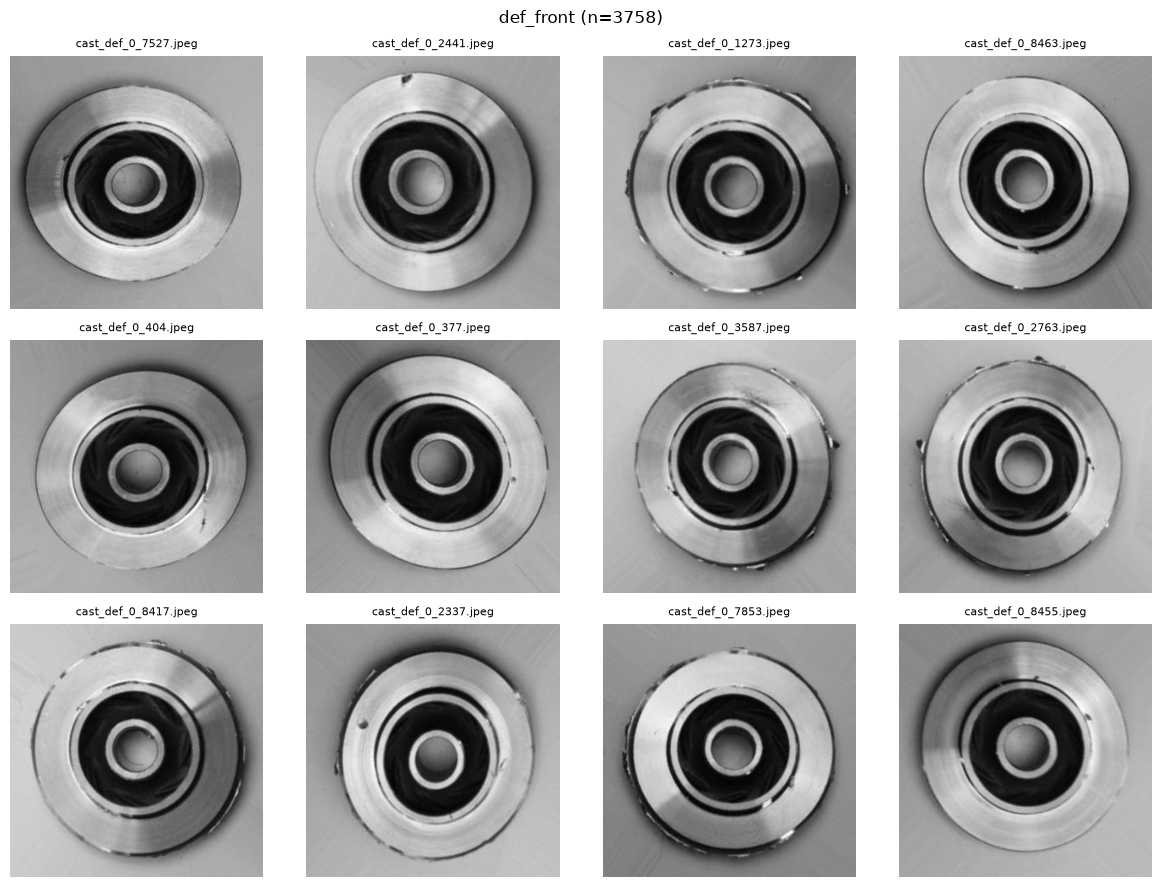

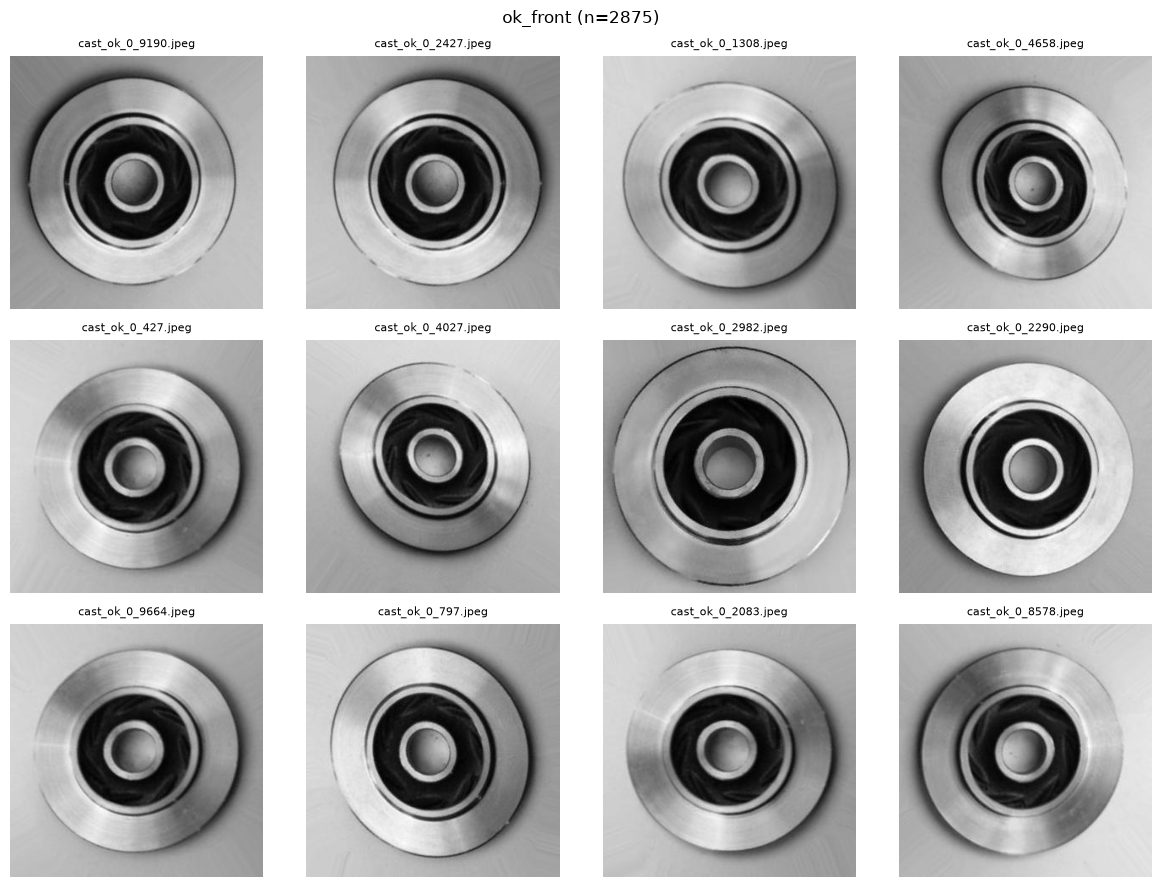

In [13]:
show_samples(DATA / "def_front")
show_samples(DATA / "ok_front")

## Properties of every image

In [15]:
import numpy as np
import pandas as pd

ROOT = Path("../data/raw/casting_data/casting_data") 

In [16]:
rows = []

for split in ["train", "test"]:
    for label in ["def_front", "ok_front"]:
        for p in sorted((ROOT / split / label).iterdir()):
            if p.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
                continue
            with Image.open(p) as img:
                arr = np.asarray(img)
                rows.append({
                    "split": split,
                    "label": label,
                    "file": p.name,
                    "width": img.size[0],
                    "height": img.size[1],
                    "mode": img.mode,
                    "channels": 1 if arr.ndim == 2 else arr.shape[2],
                    # True if R, G and B are identical, i.e. a gray image stored as colour
                    "gray_in_rgb": arr.ndim == 3 and bool((arr[..., 0] == arr[..., 1]).all() and (arr[..., 1] == arr[..., 2]).all()),
                    "brightness": arr.mean(),
                })


In [17]:
df = pd.DataFrame(rows)
print(len(df), "images")
print(df.groupby(["split", "label"]).size(), "\n")
print(df[["width", "height"]].value_counts(), "\n")
print(df["mode"].value_counts(), "\n")
print(df["gray_in_rgb"].value_counts(), "\n")
print(df.groupby("label")["brightness"].describe())

7348 images
split  label    
test   def_front     453
       ok_front      262
train  def_front    3758
       ok_front     2875
dtype: int64 

width  height
300    300       7348
Name: count, dtype: int64 

mode
RGB    7348
Name: count, dtype: int64 

gray_in_rgb
True    7348
Name: count, dtype: int64 

            count        mean       std         min         25%         50%  \
label                                                                         
def_front  4211.0  139.255834  5.808801  124.286322  135.160000  138.837556   
ok_front   3137.0  149.774729  6.479577  123.840700  143.028511  151.899011   

                  75%         max  
label                              
def_front  142.506783  157.016611  
ok_front   154.075833  160.617278  


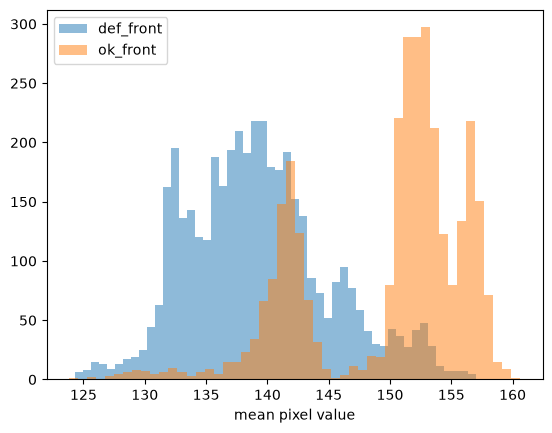

In [18]:
for label, g in df.groupby("label"):
    plt.hist(g["brightness"], bins=50, alpha=0.5, label=label)
plt.xlabel("mean pixel value"); plt.legend(); plt.show()


## Corrupted files

In [19]:
bad = []
for split in ["train", "test"]:
    for p in sorted((ROOT / split).rglob("*")):
        if p.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
            continue
        try:
            with Image.open(p) as img:
                img.verify()      # checks file structure
            with Image.open(p) as img:
                img.load()        # verify() doesn't decode pixels, so load fully too
        except Exception as e:
            bad.append((p, repr(e)))

print(len(bad), "corrupted files")
for b in bad[:10]:
    print(b)

0 corrupted files
